In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.11.0+cu130
CUDA available: True


In [ ]:

import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:
transform = transforms.ToTensor()

In [ ]:
train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))

Training samples: 60000
Testing samples: 10000


In [ ]:
train_loader = DataLoader(
    train_data, batch_size=64, shuffle = True
 )
test_loader = DataLoader(
    test_data, batch_size= 64, shuffle = True
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Training batches: 938
Testing batches: 157


In [ ]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("First 10 labels:", labels[:10])

Images shape: torch.Size([64, 1, 28, 28])
Labels shape: torch.Size([64])
First 10 labels: tensor([3, 3, 3, 2, 1, 0, 4, 3, 6, 8])


ANN Model From Pytorch

In [ ]:
class ANNModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten()

        self.network = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(256, 64),
            nn.ReLU(),

            nn.Linear(64, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        x = self.network(x)
        return x

In [ ]:
model = ANNModel()
print(model)

ANNModel(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (network): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ANNModel().to(device)

print("Device:", device)

Device: cuda


In [ ]:
images, labels = next(iter(train_loader))

images = images.to(device)

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("First image scores:", outputs[0])

Input shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])
First image scores: tensor([ 0.0508, -0.1108,  0.0171,  0.1773,  0.1011, -0.0807,  0.0145, -0.0111,
         0.0493, -0.1093], device='cuda:0')


In [ ]:
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(model.parameters(), lr = 0.0001)

print("Loss function:", loss_fn)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)


In [ ]:
epochs = 10

for epoch in range(epochs):

    model.train()

    total_loss = 0

    for images, labels in train_loader:

        # Step 1: Data ko GPU par bhejo
        images = images.to(device)
        labels = labels.to(device)

        # Step 2: Purane gradients clear karo
        optimizer.zero_grad()

        # Step 3: Forward pass
        outputs = model(images)

        # Step 4: Loss calculate karo
        loss = loss_fn(outputs, labels)

        # Step 5: Backpropagation
        loss.backward()

        # Step 6: Weights update karo
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    print(
        f"Epoch [{epoch + 1}/{epochs}], "
        f"Loss: {average_loss:.4f}"
    )

Epoch [1/10], Loss: 0.8965
Epoch [2/10], Loss: 0.5396
Epoch [3/10], Loss: 0.4783
Epoch [4/10], Loss: 0.4426
Epoch [5/10], Loss: 0.4184
Epoch [6/10], Loss: 0.3998
Epoch [7/10], Loss: 0.3845
Epoch [8/10], Loss: 0.3722
Epoch [9/10], Loss: 0.3611
Epoch [10/10], Loss: 0.3502


In [ ]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        total += labels.size(0)

        correct += (predictions == labels).sum().item()

accuracy = 100 * correct / total

print(f"Correct predictions: {correct}/{total}")
print(f"Test Accuracy: {accuracy:.2f}%")

Correct predictions: 8664/10000
Test Accuracy: 86.64%


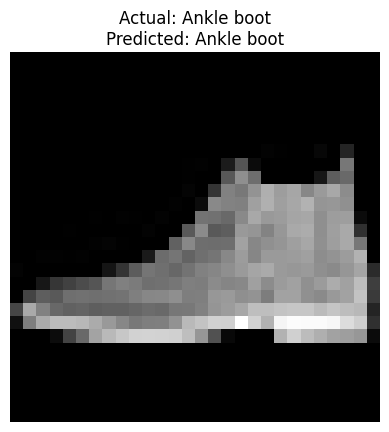

Actual label: Ankle boot
Predicted label: Ankle boot


In [ ]:
import matplotlib.pyplot as plt

# Test dataset se ek image lo
image, label = test_data[0]

# Image ko model ke device par bhejo
image = image.to(device)

# Prediction ke liye gradients ki zaroorat nahi hai
model.eval()

with torch.no_grad():
    # Ek image ko batch mein convert karo
    image_batch = image.unsqueeze(0)

    # Model se prediction lo
    output = model(image_batch)

    # Sabse bade score wali category select karo
    prediction = output.argmax(dim=1).item()

# Fashion-MNIST ki categories
classes = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

# Image display karo
plt.imshow(image.cpu().squeeze(), cmap="gray")
plt.title(
    f"Actual: {classes[label]}\n"
    f"Predicted: {classes[prediction]}"
)
plt.axis("off")
plt.show()

print("Actual label:", classes[label])
print("Predicted label:", classes[prediction])

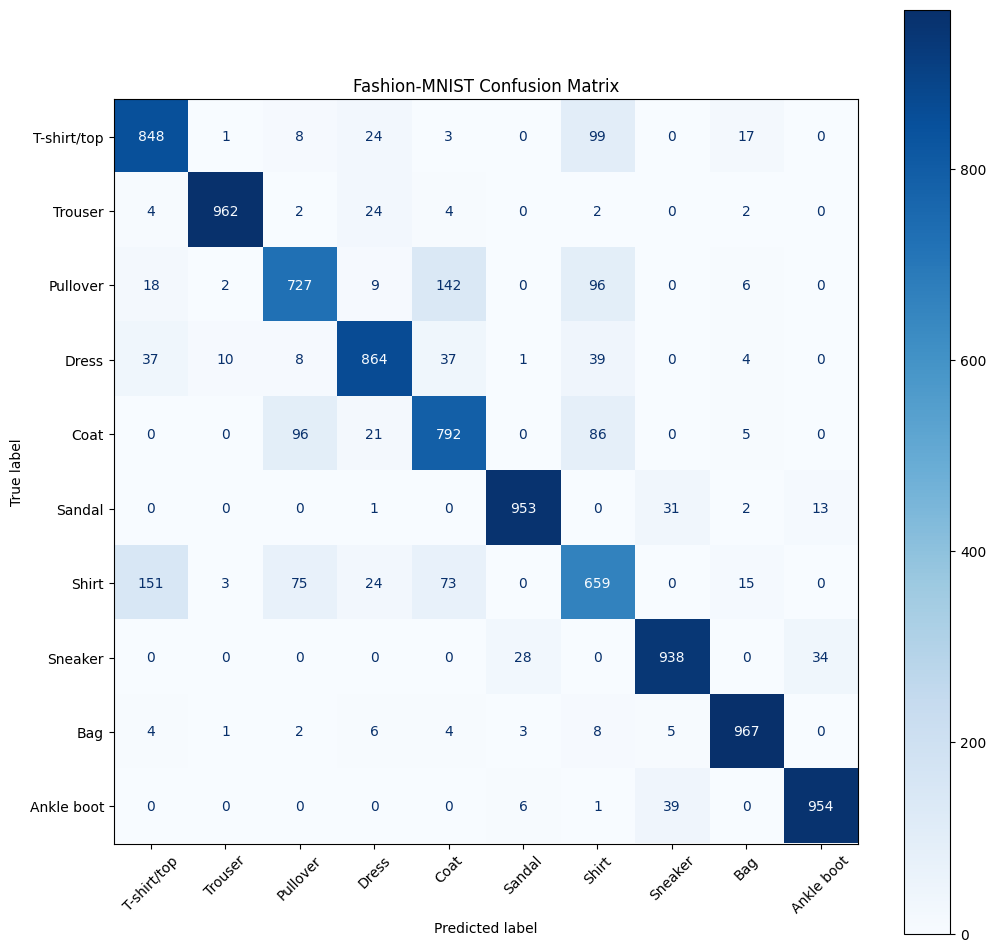

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import torch

# Model ko evaluation mode mein rakho
model.eval()

# Actual aur predicted labels store karne ke liye lists
all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        # Images aur labels ko GPU/CPU par bhejo
        images = images.to(device)
        labels = labels.to(device)

        # Model se predictions nikalo
        outputs = model(images)

        # Har image ke liye highest-score wali category
        predictions = outputs.argmax(dim=1)

        # Actual aur predicted labels CPU par store karo
        all_labels.extend(labels.cpu().tolist())
        all_predictions.extend(predictions.cpu().tolist())


# Confusion Matrix calculate karo
cm = confusion_matrix(
    all_labels,
    all_predictions
)

# Class names
classes = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

# Matrix ko visualize karo
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

fig, ax = plt.subplots(figsize=(12, 12))

display.plot(
    ax=ax,
    xticks_rotation=45,
    cmap="Blues",
    values_format="d"
)

plt.title("Fashion-MNIST Confusion Matrix")
plt.show()

In [ ]:
import matplotlib.pyplot as plt

model.eval()

wrong_images = []
wrong_actual = []
wrong_predicted = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        # Sirf galat predictions select karo
        wrong_indices = (predictions != labels).nonzero(as_tuple=True)[0]

        for idx in wrong_indices:
            wrong_images.append(images[idx].cpu())
            wrong_actual.append(labels[idx].item())
            wrong_predicted.append(predictions[idx].item())

        # Filhaal 10 galat images kaafi hain
        if len(wrong_images) >= 10:
            break

print("Wrong predictions collected:", len(wrong_images))

Wrong predictions collected: 12


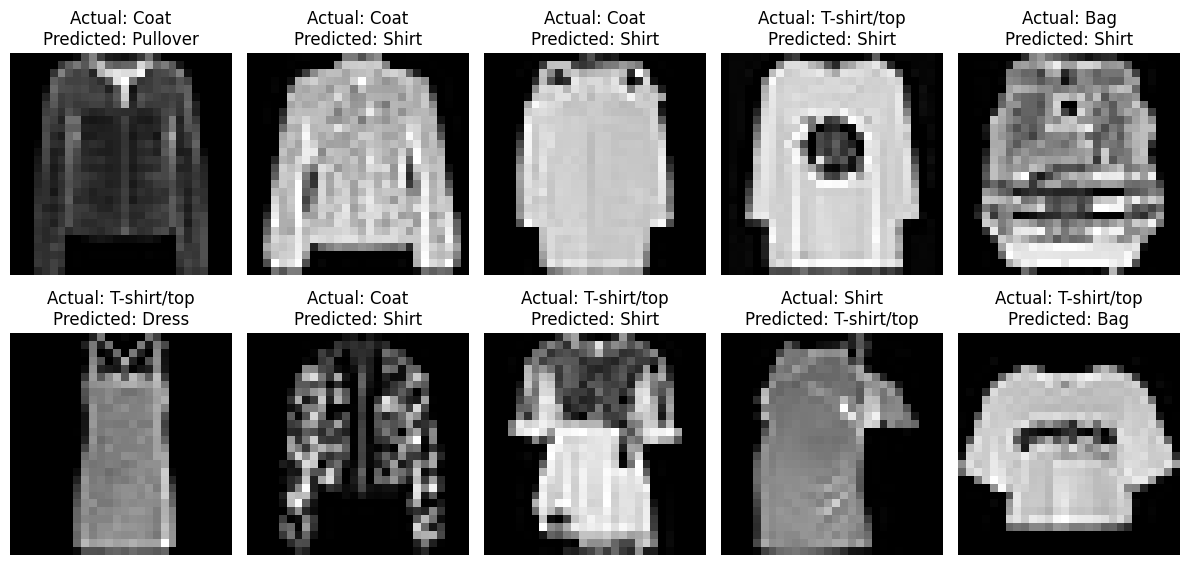

In [ ]:
plt.figure(figsize=(12, 6))

for i in range(min(10, len(wrong_images))):
    plt.subplot(2, 5, i + 1)

    plt.imshow(wrong_images[i].squeeze(), cmap="gray")

    actual = classes[wrong_actual[i]]
    predicted = classes[wrong_predicted[i]]

    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import torch
import torch.nn as nn

loss_fn = nn.CrossEntropyLoss()

# Training aur testing loss calculate karne ka function
def calculate_loss(data_loader):

    model.eval()
    total_loss = 0
    total_images = 0

    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = loss_fn(outputs, labels)

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            total_images += batch_size

    average_loss = total_loss / total_images

    return average_loss


train_loss = calculate_loss(train_loader)
test_loss = calculate_loss(test_loader)

print(f"Training Loss: {train_loss:.4f}")
print(f"Testing Loss: {test_loss:.4f}")

Training Loss: 0.3300
Testing Loss: 0.3762


In [ ]:
torch.save(model.state_dict(), "fashion_ann.pth")

In [ ]:
import os

print(os.path.exists("fashion_ann.pth"))

True


In [ ]:
def calculate_accuracy(data_loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total


print("Training Accuracy:", calculate_accuracy(train_loader))
print("Testing Accuracy:", calculate_accuracy(test_loader))

Training Accuracy: 88.235
Testing Accuracy: 86.64


In [96]:
train_losses = []
test_losses = []

epochs = 5

for epoch in range(epochs):

    # Training mode
    model.train()
    running_train_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = loss_fn(outputs, labels)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()

    epoch_train_loss = running_train_loss / len(train_loader)
    train_losses.append(epoch_train_loss)

    # Testing mode
    model.eval()
    running_test_loss = 0.0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = loss_fn(outputs, labels)

            running_test_loss += loss.item()

    epoch_test_loss = running_test_loss / len(test_loader)
    test_losses.append(epoch_test_loss)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Test Loss: {epoch_test_loss:.4f}"
    )

Epoch 1/5 | Train Loss: 0.3430 | Test Loss: 0.3680
Epoch 2/5 | Train Loss: 0.3349 | Test Loss: 0.3679
Epoch 3/5 | Train Loss: 0.3265 | Test Loss: 0.3604
Epoch 4/5 | Train Loss: 0.3210 | Test Loss: 0.3610
Epoch 5/5 | Train Loss: 0.3145 | Test Loss: 0.3516


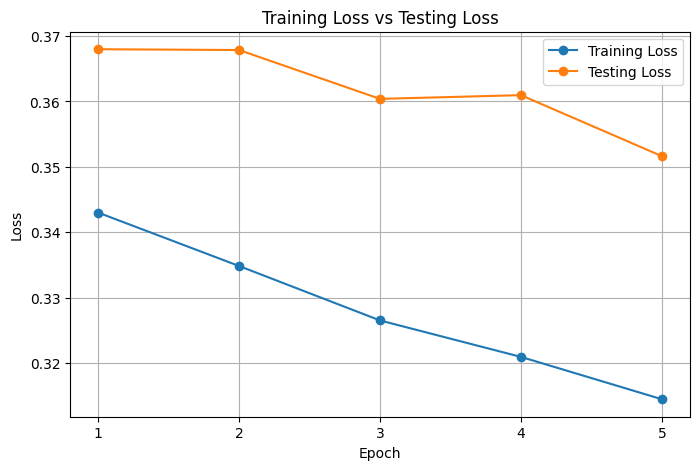

In [97]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(train_losses) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs_range, train_losses, marker='o', label='Training Loss')
plt.plot(epochs_range, test_losses, marker='o', label='Testing Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss vs Testing Loss")

plt.xticks(list(epochs_range))
plt.legend()
plt.grid(True)

plt.show()